https://www.kaggle.com/code/darshan1504/exploring-diffusion-models-with-jax

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Layer
import keras
import time
from matplotlib import pyplot as plt

tf.random.set_seed(42)

# keras.config.set_dtype_policy("mixed_float16")

# strategy = tf.distribute.MirroredStrategy()
# NUM_REPLICAS = strategy.num_replicas_in_sync

# print(f"Number of devices: {NUM_REPLICAS}")
print("GPU is available: " if tf.config.list_physical_devices('GPU') else "NOT AVAILABLE")

GPU is available: 


In [16]:
IMAGE_SIZE = 64
BATCH_SIZE = 64                            # per-GPU
GLOBAL_BATCH_SIZE = BATCH_SIZE             # total across replicas
CHANNELS = 3
EPOCHS = 250
TIMESTEPS = 1000
LEARNING_RATE = 1e-4
FILE_NAME = "multiclass-new.weights.h5"
MODEL_NAME = "multiclass-new.keras"
IS_TRAINING = False

print(IMAGE_SIZE, BATCH_SIZE, GLOBAL_BATCH_SIZE, CHANNELS, EPOCHS, TIMESTEPS, LEARNING_RATE, FILE_NAME)

64 64 64 3 250 1000 0.0001 multiclass-new.weights.h5


Found 9892 files belonging to 2 classes.
Classes found: ['dog', 'cat']


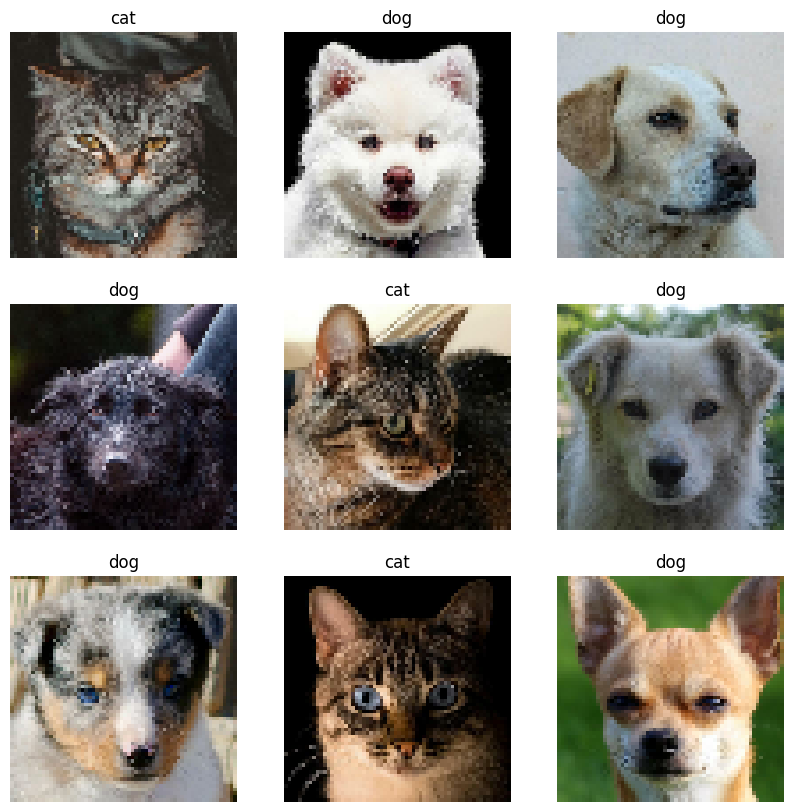

Dataset is ready for training with 155 batches


2026-05-30 10:29:09.799702: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
DATASET_PATH = 'datasets/train'

def preprocess(images, label):
    images = tf.cast(images, tf.float32)
    images = (images / 127.5) - 1.0
    return images, label

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    class_names=["dog", "cat"],
    labels="inferred",
    label_mode="int",
    color_mode='rgb',
    batch_size=GLOBAL_BATCH_SIZE,  # global batch; strategy will shard it across replicas
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    shuffle=True,
    seed=42,
    interpolation='bilinear',
)

class_names = train_ds.class_names
print("Classes found:", class_names)

train_ds = train_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
x_train = train_ds.cache().shuffle(buffer_size=1000).prefetch(buffer_size=tf.data.AUTOTUNE)

BATCHES_PER_EPOCH = int(x_train.cardinality().numpy())
TOTAL_STEPS = BATCHES_PER_EPOCH * EPOCHS

for images, labels in x_train.take(1):
    images_to_plot = (images + 1.0) / 2.0
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images_to_plot[i])
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")
    plt.show()

print(f"Dataset is ready for training with {BATCHES_PER_EPOCH} batches")

$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \alpha_t} \epsilon$$

$$noisy \space image = \sqrt{\bar{\alpha}_t} \times image + \sqrt{1- \bar{\alpha}_t} \times noise$$

In [18]:
# create a fixed linear beta schedule
def linear_noise_schedule():
    beta_start = 0.0001
    beta_end = 0.02
    beta = tf.linspace(beta_start, beta_end, TIMESTEPS)

    return beta

def cosine_noise_schedule():
    s = 0.008  # The standard offset parameter

    # 1. Create a tensor of timesteps from 0 to TIMESTEPS
    t = tf.range(0, TIMESTEPS, dtype=tf.float32)

    # 2. Implement the f(t) cosine function
    # f(t) = cos(((t / T + s) / (1 + s)) * (pi / 2)) ** 2
    phase = ((t / TIMESTEPS) + s) / (1.0 + s)
    f_t = tf.square(tf.cos(phase * (np.pi / 2.0)))

    # 3. Calculate alpha_bar (normalized by f(0))
    f_0 = tf.square(tf.cos((s / (1.0 + s)) * (np.pi / 2.0)))
    alpha_bar = f_t / f_0

    # 4. Derive beta from alpha_bar: beta_t = 1 - (alpha_bar_t / alpha_bar_{t-1})
    # To do this safely, we pad alpha_bar at the beginning with 1.0
    alpha_bar_shifted = tf.concat([tf.constant([1.0]), alpha_bar[:-1]], axis=0)
    beta = 1.0 - (alpha_bar / alpha_bar_shifted)

    # 5. Clip beta to prevent it from exploding near the end of the schedule
    beta = tf.clip_by_value(beta, clip_value_min=0.0, clip_value_max=0.999)

    return beta

def get_scheduler(mode=None):
    if mode == "linear":
        return linear_noise_schedule()
    else:
        return cosine_noise_schedule()


beta = get_scheduler()
alpha = 1.0 - beta
alpha_bar = tf.math.cumprod(alpha, axis=0)

sqrt_alpha_bar = tf.math.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = tf.math.sqrt(1-alpha_bar)


# this function will add noise to the input as per the given timestamp
@tf.function(jit_compile=True)
def forward_noise(x_0, t):
    noise = tf.random.normal(shape=tf.shape(x_0), dtype=tf.float32)
    batch_sqrt_alpha = tf.gather(sqrt_alpha_bar, t)
    batch_sqrt_one_minus_alpha_bar = tf.gather(sqrt_one_minus_alpha_bar, t)

    reshaped_sqrt_alpha = tf.reshape(batch_sqrt_alpha, (-1, 1, 1, 1))
    reshaped_sqrt_one_minus_alpha_bar = tf.reshape(batch_sqrt_one_minus_alpha_bar, (-1, 1, 1, 1))

    # Applying the actual formula
    noisy_image = (reshaped_sqrt_alpha * x_0) + (reshaped_sqrt_one_minus_alpha_bar * noise)
    return noisy_image, noise

# this function will be used to create sample timestamps between 0 &amp; T
@tf.function(jit_compile=True)
def generate_timestamp(num):
    return tf.random.uniform(shape=[num], minval=0, maxval=TIMESTEPS, dtype=tf.int32)

In [19]:
def plot_noise_progression(single_image):
    if len(single_image.shape) == 3:
        x_0 = tf.expand_dims(single_image, axis=0)
    else:
        x_0 = tf.cast(single_image, tf.float32)

    x_0 = tf.cast(x_0, tf.float32)
    intervals = list(range(0, TIMESTEPS, 100))    
    plt.figure(figsize=(18, 3))
    
    for i, t_val in enumerate(intervals):
        t_tensor = tf.constant([t_val], dtype=tf.int32)
        noisy_img, _ = forward_noise(x_0, t_tensor)
        plot_img = tf.squeeze(noisy_img, axis=0).numpy()
        
        plot_img = (plot_img + 1.0) / 2.0
        plot_img = np.clip(plot_img, 0.0, 1.0)
        
        plt.subplot(1, len(intervals), i + 1)
        plt.imshow(plot_img)
        plt.title(fontsize=10, label=t_val)
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# for images, labels in x_train.take(1):
#     single_image = images[0] # Shape becomes (64, 64, 3)
#     plot_noise_progression(single_image)
#     break

In [20]:
class SinusoidalPosEmb(Layer):
    def __init__(self, dim=64, max_positions=10000):
        super(SinusoidalPosEmb, self).__init__()
        self.dim = dim
        self.max_positions = max_positions

    def call(self, x, training=True):
        x = tf.cast(x, tf.float32)
        half_dim = self.dim // 2

        emb = tf.math.log(tf.cast(self.max_positions, tf.float32)) / (half_dim - 1)
        emb = tf.math.exp(tf.range(half_dim, dtype=tf.float32) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = tf.concat([tf.math.sin(emb), tf.math.cos(emb)], axis=-1)

        return emb

class TimeEmbedding(Layer):
    def __init__(self, dim=64, **kwargs):
        super(TimeEmbedding, self).__init__(**kwargs)
        self.time_emb = 4*dim

        self.emb = SinusoidalPosEmb(dim)
        self.dense1 = layers.Dense(self.time_emb)
        self.act = layers.Activation("swish")
        self.dense2 = layers.Dense(self.time_emb)

    def call(self, x, training=True):
        x = self.emb(x)
        x = self.dense1(x)
        x = self.act(x)
        x = self.dense2(x)
        return x

class LabelEmbedding(Layer):
    def __init__(self, num_classes, dim=64, **kwargs):
        super(LabelEmbedding, self).__init__(**kwargs)
        self.dim = dim
        self.time_emb_dim = 4 * dim

        self.emb_layer = layers.Embedding(num_classes, self.time_emb_dim)

    def call(self, x, training=True):
        return self.emb_layer(x)


class Attention(Layer):
    def __init__(self, dim, num_heads=4, **kwargs):
        super(Attention, self).__init__(**kwargs)
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads 
        
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=self.head_dim)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        h, w = x.shape[1], x.shape[2]
        
        flat_x = tf.reshape(x, (batch_size, h*w, self.dim))
        attn_x = self.mha(flat_x, flat_x)
        
        out_x = tf.reshape(attn_x, (batch_size, h, w, self.dim))
        return out_x

class Block(Layer):
    def __init__(self, dim=64, **kwargs):
        super(Block, self).__init__(**kwargs)
        self.conv = layers.Conv2D(dim, (3,3), padding="same")
        self.norm = layers.GroupNormalization(groups=8)
        self.act = layers.Activation("swish")
    
    def call(self, x, training=True):
        x = self.conv(x)
        x = self.norm(x)
        x = self.act(x)
        return x

class ResNetBlock(layers.Layer):
    def __init__(self, out_channels=64, **kwargs):
        super(ResNetBlock, self).__init__(**kwargs)
        self.out_channels = out_channels
        
        # Conv blocks
        self.conv_block1 = Block(out_channels)
        self.conv_block2 = Block(out_channels)
        self.res_conv = layers.Conv2D(out_channels, 1, padding="same")

        # Dynamic Modulation: Predicts BOTH Scale (gamma) and Shift (beta)
        # We output 2 * out_channels
        self.context_dense = layers.Dense(2 * out_channels)
        self.context_act = layers.Activation("swish")

    def call(self, x, context_emb=None):
        input_x = x
        
        # 1. Pass through first convolution
        h = self.conv_block1(input_x)

        # 2. Inject Time & Label via Scale-Shift Modulation
        if context_emb is not None:
            # Process the combined context
            # c = tf.squeeze(context_emb, axis=1)
            c = context_emb[:, 0, :]
            c = self.context_act(c)
            c = self.context_dense(c) # Shape: (Batch, 2 * out_channels)
            
            # Unpack into scale (gamma) and shift (beta)
            c = tf.expand_dims(tf.expand_dims(c, 1), 1) # Shape: (Batch, 1, 1, 2 * out_channels)
            gamma, beta = tf.split(c, num_or_size_splits=2, axis=-1)
            
            # Modulate the feature map actively
            h = h * (1.0 + gamma) + beta

        # 3. Finish block
        h = self.conv_block2(h)
        return h + self.res_conv(input_x)

In [21]:
def build_unet(img_size):
    dim = 64
    dim_scale_factor = (1, 2, 4, 8)
    ATTN_RESOLUTIONS = (16, 8)
    num_groups = 8
    channels = CHANNELS

    image_input = layers.Input(shape=(img_size, img_size, channels), name="image_input")
    time_input = layers.Input(shape=(1,), name="time_input")
    label_input = layers.Input(shape=(1,), name="label_input")

    t_emb = TimeEmbedding(dim)(time_input)
    l_emb = LabelEmbedding(num_classes=2, dim=dim)(label_input)
    context_emb = layers.Concatenate(axis=-1)([t_emb, l_emb])

    x = layers.Conv2D(dim, kernel_size=7, padding="same")(image_input)

    skips = []
    dims = [dim * i for i in dim_scale_factor]

    # Downsampling path
    for index, current_dim in enumerate(dims):
        current_res = img_size // (2 ** index)

        x = ResNetBlock(current_dim)(x, context_emb)
        x = ResNetBlock(current_dim)(x, context_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        skips.append(x)

        if index != len(dims) - 1:
            x = layers.Conv2D(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # Bottleneck
    mid_dim = dims[-1]
    x = ResNetBlock(mid_dim)(x, context_emb)
    attn = Attention(mid_dim)(x)
    norm = layers.GroupNormalization(groups=num_groups)(attn)
    x = norm + x
    x = ResNetBlock(mid_dim)(x, context_emb)

    # Upsampling path
    for index, current_dim in enumerate(reversed(dims)):
        current_res = img_size // (2 ** (len(dims) - 1 - index))

        skip_layer = skips.pop()
        x = layers.Concatenate()([skip_layer, x])

        x = ResNetBlock(current_dim)(x, context_emb)
        x = ResNetBlock(current_dim)(x, context_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        if index != len(dims) - 1:
            x = layers.Conv2DTranspose(current_dim, kernel_size=4, strides=2, padding="same")(x)

    x = ResNetBlock(dim)(x, context_emb)
    output = layers.Conv2D(channels, kernel_size=1, padding="same", dtype="float32")(x)

    return models.Model(inputs=[image_input, time_input, label_input], outputs=output, name="UNet")



model = build_unet(img_size=IMAGE_SIZE)
model.summary()

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=LEARNING_RATE,
    decay_steps=TOTAL_STEPS,
    alpha=0.1
)
optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)
loss_fn = tf.keras.losses.MeanSquaredError()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ time_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label_input         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_embedding      │ (None, 1, 256)    │     82,432 │ time_input[0][0]  │
│ (TimeEmbedding)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label_embedding     │ (None, 1, 256)    │        512 │ label_input[0][0] │
│ (LabelEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      9,472 │ image_input[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1, 512)    │          0 │ time_embedding[0… │
│ (Concatenate)       │                   │            │ label_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block       │ (None, 64, 64,    │    143,936 │ conv2d[0][0],     │
│ (ResNetBlock)       │ 64)               │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_1     │ (None, 64, 64,    │    143,936 │ res_net_block[0]… │
│ (ResNetBlock)       │ 64)               │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │     65,600 │ res_net_block_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_2     │ (None, 32, 32,    │    361,600 │ conv2d_7[0][0],   │
│ (ResNetBlock)       │ 128)              │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_3     │ (None, 32, 32,    │    443,520 │ res_net_block_2[… │
│ (ResNetBlock)       │ 128)              │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 16, 16,    │    262,272 │ res_net_block_3[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_4     │ (None, 16, 16,    │  1,181,952 │ conv2d_14[0][0],  │
│ (ResNetBlock)       │ 256)              │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_5     │ (None, 16, 16,    │  1,509,632 │ res_net_block_4[… │
│ (ResNetBlock)       │ 256)              │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 16, 16,    │    263,168 │ res_net_block_5[… │
│ (Attention)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        512 │ attention[0][0] 

 Total params: 54,869,059 (209.31 MB)

 Trainable params: 54,869,059 (209.31 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
@tf.function
def train_step(images, labels):
    batch_size = tf.shape(images)[0]
    images = tf.cast(images, tf.float32)

    # Generate random timesteps for each image in the batch
    t = generate_timestamp(batch_size)
    noisy_images, noise = forward_noise(images, t)

    # Convert timestep to float 
    t_float = tf.cast(t, dtype=tf.float32)
    t_float = tf.reshape(t_float, (-1, 1))

    with tf.GradientTape() as tape:
        predicted_noise = model([noisy_images, t_float, labels], training=True)
        loss = loss_fn(noise, predicted_noise)

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [23]:
print(f"Model will train for max: {TOTAL_STEPS} distributed steps")

def train_model():
    best_loss = float('inf')
    patience = 50
    wait = 0

    for epoch in range(EPOCHS):
        start_time = time.time()
        batch_start = time.time()
        epoch_loss = 0.0
        steps = 0
        batch_count = 0

        for batch_images, batch_labels in x_train:
            loss = train_step(batch_images, batch_labels)
            epoch_loss += loss
            steps += 1
            batch_count += 1
            if batch_count % 10 == 0:
                print(f"Batch {batch_count} - Loss: {loss:.4f} time taken: {time.time()-batch_start:.2f}s")
                batch_start = time.time()

        avg_loss = epoch_loss / steps
        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {avg_loss:.4f}, time taken: {time.time()-start_time:.2f}s")

        if avg_loss < best_loss:
            best_loss = avg_loss
            wait = 0
            model.save_weights(FILE_NAME)
            print("  > Loss improved. Saving model weights.")
        else:
            wait += 1
            print(f"  > No improvement. Patience: {wait}/{patience}")
            if wait >= patience:
                print("  > Early Stopping triggered!")
                model.load_weights(FILE_NAME)
                break

Model will train for max: 38750 distributed steps


In [24]:
print(FILE_NAME)
print(MODEL_NAME)

if IS_TRAINING:
    train_model()
    model.save_weights(FILE_NAME)
    model.save(MODEL_NAME)
    print("Model weights saved to", FILE_NAME)
    print("Model saved to", MODEL_NAME)
else:
    model.load_weights("weights/"+FILE_NAME)
    print("Model weights loaded from", FILE_NAME)

multiclass-new.weights.h5
multiclass-new.keras
Model weights loaded from multiclass-new.weights.h5


In [25]:
import random
from tqdm import tqdm

def backward_denoising_ddpm(x_t, pred_noise, t):
    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** 0.5
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)

    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=tf.float32)

    # At t == 0 the chain terminates with the mean; no extra noise added
    noise_mask = tf.cast(t > 0, tf.float32)
    return mean + noise_mask * (var ** 0.5) * z


def backward_denoising_ddim(x_t, pred_noise, t, sigma_t):
    alpha_bar_t = tf.gather(alpha_bar, t)

    # Guard t - 1 underflow at t = 0, and use alpha_bar_{t-1} (NOT alpha_{t-1})
    t_prev = tf.maximum(t - 1, 0)
    alpha_bar_prev = tf.where(
        t > 0,
        tf.gather(alpha_bar, t_prev),
        tf.ones_like(alpha_bar_t),
    )

    # Predict x_0 from x_t and predicted noise
    pred_x0 = (x_t - ((1.0 - alpha_bar_t) ** 0.5) * pred_noise) / (alpha_bar_t ** 0.5)

    # x_{t-1} = sqrt(alpha_bar_{t-1}) * x_0 + sqrt(1 - alpha_bar_{t-1} - sigma^2) * eps_pred + sigma * z
    mean = (alpha_bar_prev ** 0.5) * pred_x0 \
         + ((1.0 - alpha_bar_prev - sigma_t ** 2) ** 0.5) * pred_noise

    eps_t = tf.random.normal(tf.shape(x_t), dtype=tf.float32)
    return mean + sigma_t * eps_t

  0%|          | 0/1000 [00:00<?, ?it/s]

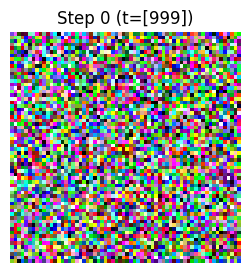

 10%|█         | 100/1000 [00:22<02:42,  5.55it/s]

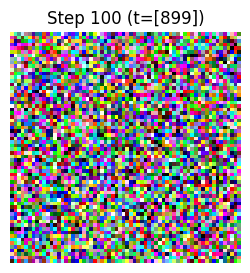

 20%|██        | 200/1000 [00:40<02:23,  5.58it/s]

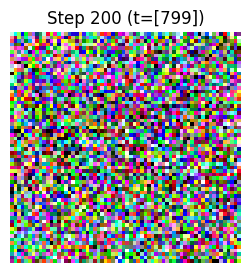

 30%|███       | 300/1000 [01:00<02:18,  5.04it/s]

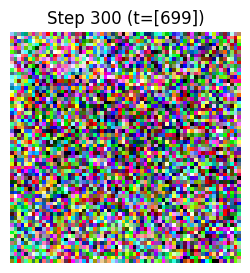

 40%|████      | 400/1000 [01:20<01:51,  5.40it/s]

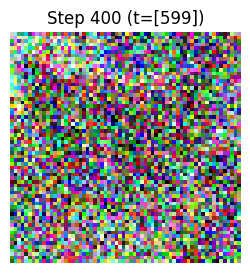

 50%|█████     | 500/1000 [01:40<01:25,  5.86it/s]

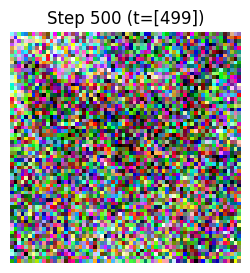

 60%|██████    | 600/1000 [01:58<01:12,  5.51it/s]

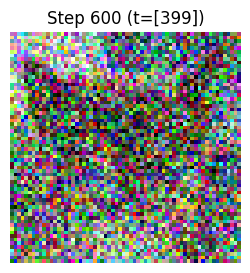

 70%|███████   | 700/1000 [02:16<00:53,  5.61it/s]

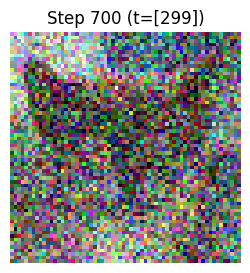

 80%|████████  | 800/1000 [02:35<00:40,  4.90it/s]

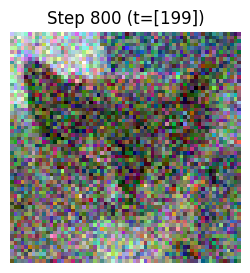

 90%|█████████ | 900/1000 [02:53<00:16,  5.90it/s]

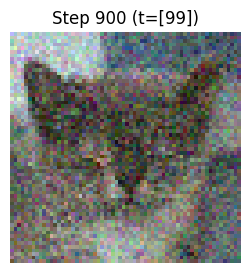

 95%|█████████▌| 950/1000 [03:02<00:08,  5.59it/s]

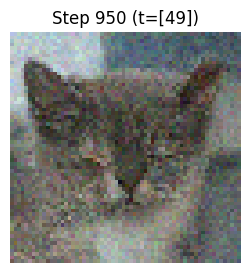

100%|██████████| 1000/1000 [03:11<00:00,  5.23it/s]


In [26]:
# Generating Gaussian noise
x = tf.random.normal((1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), dtype=tf.float32, seed=random.randint(0, 1000))
c = tf.constant([1], dtype=tf.int32) 

# Iterate over T timesteps
for i in tqdm(range(0, TIMESTEPS)):
  # t-th timestep  
  t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
  
  # Predict noise using U-Net
  pred_noise = model([x, t, c])
  
  # Obtain the output from the noise using the formula seen before
  x = backward_denoising_ddpm(x, pred_noise, t)

  # Log the image after every 25 iterations
  if i % 100 == 0 or i == 950:
    img_to_plot = x[0] 
        
    # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
    img_to_plot = (img_to_plot + 1.0) / 2.0
    
    # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
    img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

    plt.figure(figsize=(3,3))
    plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
    plt.title(f"Step {i} (t={t})")
    plt.axis('off')
    plt.show()

In [27]:
# # Create a list to store output images
# img_list_ddim = []

# # Generate some noise
# x = tf.random.normal((1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), dtype=tf.float32, seed=random.randint(0, 1000))
# c = tf.constant([1], dtype=tf.int32) 


# # Define number of inference loops to run
# inference_timesteps = 100

# # Create a range of inference steps that the output should be sampled at
# inference_range = range(0, TIMESTEPS, TIMESTEPS // inference_timesteps)

# # Iterate over inference_timesteps
# for index, i in tqdm(enumerate(reversed(range(inference_timesteps))), total=inference_timesteps):
  
#   # Fetch t for that specific timestep  
#   t = tf.expand_dims(inference_range[i], 0) 
#   print(t)
  
#   # Predict the noise  
#   pred_noise = model([x, t, c])
   
#   # Obtain the output from the noise using the formula seen before
#   x = backward_denoising_ddim(x, pred_noise, t, 0)

#   # Log and display output image at every timestep
#   if index % 10 == 0:
#     img_to_plot = x[0] 
        
#     # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
#     img_to_plot = (img_to_plot + 1.0) / 2.0
    
#     # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
#     img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

#     plt.figure(figsize=(3,3))
#     plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
#     plt.title(f"Step {index} (t={t})")
#     plt.axis('off')
#     plt.show()

# # Display the final generated image
# img_to_plot = x[0] 
        
# # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
# img_to_plot = (img_to_plot + 1.0) / 2.0

# # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
# img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

# plt.figure(figsize=(3,3))
# plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
# plt.title(f"Step {i} (t={t})")
# plt.axis('off')
# plt.show()